##Step 1: Verify the dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import torch

# Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Existing dataset paths
BASE_DIR = "/content/drive/MyDrive/PCOS_Project"
SPLIT_DIR = os.path.join(BASE_DIR, "SPLIT_DATASET")

for split in ["train", "test"]:
    print(f"\n{split.upper()} dataset:")

    for class_name in ["infected", "noninfected"]:
        folder = os.path.join(SPLIT_DIR, split, class_name)

        if not os.path.isdir(folder):
            raise FileNotFoundError(f"Missing folder: {folder}")

        count = sum(
            1 for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
        )

        print(f"{class_name}: {count} images")

print("\nDataset verification completed.")

Mounted at /content/drive
Device: cuda

TRAIN dataset:
infected: 2520 images
noninfected: 622 images

TEST dataset:
infected: 630 images
noninfected: 156 images

Dataset verification completed.


##Step 2: Create Data Loaders

In [ ]:


import os
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Dataset path
BASE_DIR = "/content/drive/MyDrive/PCOS_Project"
SPLIT_DIR = os.path.join(BASE_DIR, "SPLIT_DATASET")

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Image settings
IMAGE_SIZE = 224
BATCH_SIZE = 32

# ImageNet normalization
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Training transforms: augmentation only for training
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(5),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

# Test transforms: no random augmentation
test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

# Load datasets
train_dataset = datasets.ImageFolder(
    os.path.join(SPLIT_DIR, "train"),
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    os.path.join(SPLIT_DIR, "test"),
    transform=test_transform
)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Verify configuration
print("\nClass mapping:", train_dataset.class_to_idx)
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

images, labels = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Device: cuda

Class mapping: {'infected': 0, 'noninfected': 1}
Training images: 3142
Testing images: 786
Training batches: 99
Testing batches: 25
Batch image shape: torch.Size([32, 3, 224, 224])
Batch label shape: torch.Size([32])


##

##Step 3: Load the pretrained Swin Transformer

In [ ]:


import torch
import torch.nn as nn
from torchvision import models

# Load pretrained Swin-Tiny
weights = models.Swin_T_Weights.DEFAULT
model = models.swin_t(weights=weights)

# Replace the classification head for 2 classes
num_features = model.head.in_features
model.head = nn.Linear(num_features, 2)

# Move model to GPU
model = model.to(device)

print("Model: Swin Transformer Tiny (Swin-T)")
print("Pretrained weights: ImageNet")
print("Input image size:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Input features:", num_features)
print("Output classes:", model.head.out_features)
print("Device:", device)
print("Swin Transformer loaded successfully!")

Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:00<00:00, 119MB/s]


Model: Swin Transformer Tiny (Swin-T)
Pretrained weights: ImageNet
Input image size: 224 x 224
Input features: 768
Output classes: 2
Device: cuda
Swin Transformer loaded successfully!


##Step 4: Configure loss function and optimizer

In [ ]:
import torch.nn as nn
import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

# Verify configuration
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Loss function:", criterion)
print("Optimizer: Adam")
print("Learning rate:", 0.0001)
print("Trainable parameters:", f"{trainable_params:,}")
print("Swin Transformer training configuration ready!")

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.0001
Trainable parameters: 27,520,892
Swin Transformer training configuration ready!


##Step 5: Train Swin Transformer for 5 epochs

In [ ]:
import time
import torch

num_epochs = 5

# Store training history for plotting later
train_losses = []
train_accuracies = []

for epoch in range(num_epochs):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0
    start_time = time.time()

    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        if (batch_idx + 1) % 10 == 0 or (batch_idx + 1) == len(train_loader):
            print(
                f"Epoch [{epoch + 1}/{num_epochs}] "
                f"Batch [{batch_idx + 1}/{len(train_loader)}]"
            )

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    elapsed = (time.time() - start_time) / 60

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {epoch_accuracy:.2f}% | "
        f"Time: {elapsed:.2f} min"
    )

print("\nSwin Transformer training completed!")
print("Training loss history:", train_losses)
print("Training accuracy history:", train_accuracies)

Epoch [1/5] Batch [10/99]
Epoch [1/5] Batch [20/99]
Epoch [1/5] Batch [30/99]
Epoch [1/5] Batch [40/99]
Epoch [1/5] Batch [50/99]
Epoch [1/5] Batch [60/99]
Epoch [1/5] Batch [70/99]
Epoch [1/5] Batch [80/99]
Epoch [1/5] Batch [90/99]
Epoch [1/5] Batch [99/99]
Epoch [1/5] Loss: 0.1012 | Accuracy: 96.75% | Time: 9.23 min
Epoch [2/5] Batch [10/99]
Epoch [2/5] Batch [20/99]
Epoch [2/5] Batch [30/99]
Epoch [2/5] Batch [40/99]
Epoch [2/5] Batch [50/99]
Epoch [2/5] Batch [60/99]
Epoch [2/5] Batch [70/99]
Epoch [2/5] Batch [80/99]
Epoch [2/5] Batch [90/99]
Epoch [2/5] Batch [99/99]
Epoch [2/5] Loss: 0.0461 | Accuracy: 98.82% | Time: 0.78 min
Epoch [3/5] Batch [10/99]
Epoch [3/5] Batch [20/99]
Epoch [3/5] Batch [30/99]
Epoch [3/5] Batch [40/99]
Epoch [3/5] Batch [50/99]
Epoch [3/5] Batch [60/99]
Epoch [3/5] Batch [70/99]
Epoch [3/5] Batch [80/99]
Epoch [3/5] Batch [90/99]
Epoch [3/5] Batch [99/99]
Epoch [3/5] Loss: 0.0347 | Accuracy: 99.08% | Time: 0.75 min
Epoch [4/5] Batch [10/99]
Epoch [4/5]

##Step 6: Save the Swin Transformer checkpoint

In [ ]:
import os
import torch

SAVE_DIR = (
    "/content/drive/MyDrive/PCOS_Project/model_checkpoints"
)
os.makedirs(SAVE_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    SAVE_DIR, "swin_tiny_baseline.pth"
)

torch.save({
    "model_state_dict": model.state_dict(),
    "class_to_idx": train_dataset.class_to_idx,
    "epochs_trained": 5,
    "image_size": IMAGE_SIZE,
    "train_losses": train_losses,
    "train_accuracies": train_accuracies
}, checkpoint_path)

print("Swin Transformer checkpoint saved successfully!")
print("Saved to:", checkpoint_path)
print(
    "File size (MB):",
    round(os.path.getsize(checkpoint_path) / (1024 * 1024), 2)
)

Swin Transformer checkpoint saved successfully!
Saved to: /content/drive/MyDrive/PCOS_Project/model_checkpoints/swin_tiny_baseline.pth
File size (MB): 105.27


##Step 7: Evaluate Swin Transformer

In [ ]:
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Rebuild Swin-Tiny architecture
model_eval = models.swin_t(weights=None)
model_eval.head = nn.Linear(model_eval.head.in_features, 2)

# Load saved checkpoint
checkpoint_path = (
    "/content/drive/MyDrive/PCOS_Project/"
    "model_checkpoints/swin_tiny_baseline.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model_eval.load_state_dict(checkpoint["model_state_dict"])
model_eval = model_eval.to(device)
model_eval.eval()

# Generate predictions
y_true = []
y_pred = []
y_prob = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_eval(images)
        probabilities = torch.softmax(outputs, dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(
            probabilities.argmax(dim=1).cpu().numpy()
        )
        y_prob.extend(
            probabilities[:, 1].cpu().numpy()
        )

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
auc = roc_auc_score(y_true, y_prob)

print("Swin Transformer Baseline — Test Results")
print("=" * 45)
print(f"Test images: {len(y_true)}")
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["infected", "noninfected"],
    digits=4,
    zero_division=0
))

print("Confusion Matrix:")
print(cm)
print(f"\nROC-AUC (noninfected positive class): {auc:.4f}")

Swin Transformer Baseline — Test Results
Test images: 786
Accuracy: 98.60%

Classification Report:
              precision    recall  f1-score   support

    infected     0.9905    0.9921    0.9913       630
 noninfected     0.9677    0.9615    0.9646       156

    accuracy                         0.9860       786
   macro avg     0.9791    0.9768    0.9780       786
weighted avg     0.9860    0.9860    0.9860       786

Confusion Matrix:
[[625   5]
 [  6 150]]

ROC-AUC (noninfected positive class): 0.9962


##Step 9: Plot the confusion matrix and ROC curve

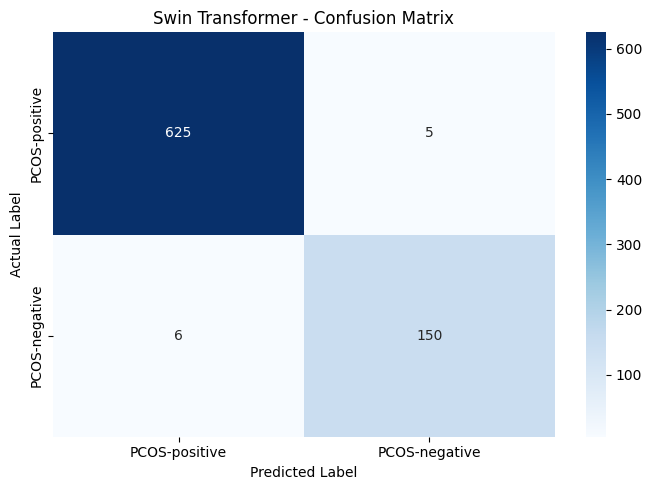

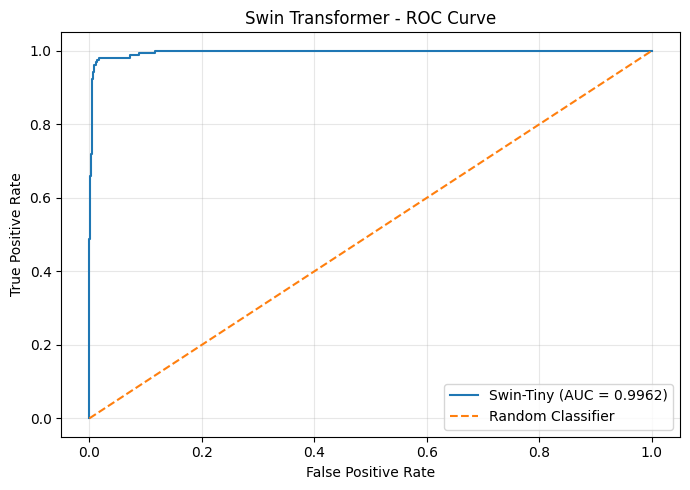

Swin Transformer plots saved successfully.
ROC-AUC: 0.9962


In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

PLOT_DIR = "/content/drive/MyDrive/PCOS_Project"
os.makedirs(PLOT_DIR, exist_ok=True)

# 1. Confusion Matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["PCOS-positive", "PCOS-negative"],
    yticklabels=["PCOS-positive", "PCOS-negative"]
)
plt.title("Swin Transformer - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "swin_tiny_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 2. ROC Curve
fpr, tpr, _ = roc_curve(y_true, y_prob, pos_label=1)
auc_score = roc_auc_score(y_true, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Swin-Tiny (AUC = {auc_score:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Swin Transformer - ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "swin_tiny_roc_curve.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Swin Transformer plots saved successfully.")
print("ROC-AUC:", round(auc_score, 4))